# 06 — Movement measurement reliability (Phase 03 · M2, Family G)

**Status: authored, NOT executed. User validation required.**

## 1. Research objective
A theoretically interesting metric is useless if it cannot be measured consistently. For every Combine drill × feature, quantify how well **one attempt** ranks athletes (ICC(1) with athlete-bootstrap 95 % CI), the reliability of an athlete's **mean** over attempts (ICC(1,k̄)), the typical error, rank stability between the first two attempts and learning/fatigue drift — pooled and per cohort.

## 2. Data sources
`combine_attempt_features`, `combine_sprint_profiles` (M2) → `reports/tables/phase_03/feature_reliability.csv` (written by `python -m nflbdb.research.combine_analytics`). The unit of analysis is the athlete; only athletes with ≥ 2 usable attempts of the same canonical drill enter.

In [1]:
# 3. Efficient loading
from nflbdb.data.config import Phase01Config, configure_runtime
cfg = Phase01Config.load(); configure_runtime(cfg)

import polars as pl
from nflbdb.research.combine_movement import CombineMovementBuilder
from nflbdb.research.combine_analytics import KEY_DRILLS, KEY_FEATURES, attempt_long, reliability_all

builder = CombineMovementBuilder(cfg)
store = builder.store
path = store.tables_dir / 'feature_reliability.csv'

In [2]:
# 4. Cached-result reuse: recompute only if the table is missing or older than the M2 datasets
#    (typed reload from the Parquet twin written by combine_analytics; CSV is for humans)
ppath = store.tables_dir / 'feature_reliability.parquet'
m2_files = [f for s in builder.specs.values() for f in store.dataset_files(s.name)]
stale = (not ppath.exists()) or any(f.stat().st_mtime > ppath.stat().st_mtime for f in m2_files)
if stale:
    long = attempt_long(builder.load('attempts').collect(), builder.load('sprint').collect())
    rel = reliability_all(long, builder.mcfg)
    store.export_csv(rel, 'feature_reliability', 'Phase 03 M2: feature_reliability', parquet=True)
else:
    rel = pl.read_parquet(ppath)
rel.shape, stale

((8271, 19), False)

In [3]:
# 5. Summary — pooled reliability of the key features per key drill (sorted by CI lower bound)
cols = ['feature', 'n_athletes', 'k_mean', 'icc1', 'icc1_ci_lo', 'icc1_ci_hi', 'icc1_mean_k', 'typical_error',
        'cv_within_pct', 'spearman_first_two', 'mean_diff_2_minus_1', 'reliability']
for d in KEY_DRILLS:
    print(d)
    display(rel.filter((pl.col('drill') == d) & (pl.col('cohort') == 'all'))
               .select([c for c in cols if c in rel.columns]).sort('icc1_ci_lo', descending=True, nulls_last=True))

FORTY_YARD_DASH


feature,n_athletes,k_mean,icc1,icc1_ci_lo,icc1_ci_hi,icc1_mean_k,typical_error,cv_within_pct,spearman_first_two,mean_diff_2_minus_1,reliability
str,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str
"""trk_t20_40_s""",373,2.0,0.991656,0.989721,0.993253,0.995811,0.013523,0.683278,0.987584,0.002403,"""excellent"""
"""speed_p90""",375,2.0,0.987821,0.985354,0.989969,0.993873,0.08475,0.82035,0.9827,-0.018108,"""excellent"""
"""speed_p95""",375,2.0,0.986679,0.984204,0.988857,0.993295,0.0896,0.864523,0.981026,-0.018496,"""excellent"""
"""speed_max""",375,2.0,0.984992,0.982063,0.987447,0.992439,0.095346,0.917934,0.978929,-0.021024,"""excellent"""
"""speed_max_obs""",375,2.0,0.984992,0.982063,0.987447,0.992439,0.095346,0.917934,0.978929,-0.021024,"""excellent"""
…,…,…,…,…,…,…,…,…,…,…,…
"""n_phase_transitions""",375,2.0,-0.025924,-0.037241,-0.016245,-0.053227,0.384708,36.202103,-0.034223,0.018667,"""degenerate_distribution"""
"""time_to_peak_accel_s""",375,2.0,0.081293,-0.042427,0.267897,0.150363,0.264348,null,0.160036,0.005067,"""poor"""
"""frac_time_decelerating""",375,2.0,-0.039248,-0.05865,-0.01794,-0.081703,0.011731,null,-0.036056,0.000998,"""degenerate_distribution"""


SHORT_SHUTTLE


feature,n_athletes,k_mean,icc1,icc1_ci_lo,icc1_ci_hi,icc1_mean_k,typical_error,cv_within_pct,spearman_first_two,mean_diff_2_minus_1,reliability
str,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str
"""time_above_8yds_s""",42,2.261905,NaN,NaN,NaN,null,0.0,null,NaN,0.0,"""degenerate_distribution"""
"""frac_time_lateral""",42,2.261905,0.472873,0.296102,0.569087,0.669869,0.046776,null,0.326504,0.002363,"""poor"""
"""abs_yaw_rate_p95""",42,2.261905,0.338038,0.106484,0.530446,0.535977,30.111322,44.122046,0.426141,-0.534526,"""poor"""
"""yaw_integral_deg""",42,2.261905,0.45773,0.100759,0.668219,0.656272,35.085275,38.197448,0.37655,-9.055489,"""poor"""
"""cod_approach_speed_median""",41,2.268293,0.279499,0.089003,0.442879,0.468064,0.392381,9.484987,0.529965,0.009022,"""poor"""
…,…,…,…,…,…,…,…,…,…,…,…
"""frac_time_accelerating""",42,2.261905,-0.081759,-0.37814,0.320521,-0.206206,0.097169,18.229135,0.159789,0.02601,"""poor"""
"""n_phase_transitions""",42,2.261905,-0.007634,-0.38318,0.37001,-0.017436,1.312135,null,-0.030102,-0.47619,"""poor"""
"""dist_to_peak_speed_yds""",42,2.261905,-0.113189,-0.385213,0.126171,-0.298684,4.121014,33.289992,0.125192,2.150355,"""poor"""


THREE_CONE_DRILL


feature,n_athletes,k_mean,icc1,icc1_ci_lo,icc1_ci_hi,icc1_mean_k,typical_error,cv_within_pct,spearman_first_two,mean_diff_2_minus_1,reliability
str,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str
"""cod_approach_decel_median""",38,2.131579,0.656657,0.431323,0.807499,0.803023,0.53804,18.856407,0.629281,-0.061557,"""poor"""
"""n_braking_events""",38,2.131579,0.652515,0.390432,0.845318,0.800109,0.408248,19.338077,0.710301,0.0,"""poor"""
"""braking_time_s""",38,2.131579,0.607931,0.359635,0.788055,0.767721,0.202504,18.245607,0.599832,-0.015789,"""poor"""
"""decel_mean""",38,2.131579,0.488514,0.327946,0.62272,0.670602,0.401684,13.595386,0.651165,0.140626,"""poor"""
"""braking_intensity_mean""",38,2.131579,0.557369,0.298554,0.727551,0.728565,0.300147,6.499706,0.545683,0.071863,"""poor"""
…,…,…,…,…,…,…,…,…,…,…,…
"""frac_braking_with_reaccel""",38,2.131579,-0.260664,-0.308678,-0.218537,-0.788077,0.062257,6.264397,NaN,-0.013158,"""degenerate_distribution"""
"""speed_median""",38,2.131579,-0.030658,-0.333591,0.593687,-0.067698,0.341017,13.194949,0.346756,0.115158,"""poor"""
"""frac_time_decelerating""",38,2.131579,-0.15509,-0.390005,0.15421,-0.400952,0.035523,14.816409,-0.051246,-0.009196,"""poor"""


In [4]:
# Reliability label counts across ALL drills (position drills included) and cohort comparison
display(rel.filter(pl.col('cohort') == 'all').group_by('reliability').len().sort('len', descending=True))
by_cohort = (rel.filter((pl.col('cohort') != 'all') & pl.col('icc1').is_not_null())
               .pivot(on='cohort', index=['drill', 'feature'], values='icc1'))
display(by_cohort.filter(pl.col('drill').is_in(list(KEY_DRILLS))).sort('drill', 'feature'))

reliability,len
str,u32
"""insufficient_athletes""",1515
"""poor""",537
"""insufficient_for_label""",357
"""degenerate_distribution""",106
"""moderate""",31
"""excellent""",15
"""good""",14


drill,feature,2023,2024,2025
str,str,f64,f64,f64
"""FORTY_YARD_DASH""","""a_lat_abs_p95""",0.374544,0.332593,0.15886
"""FORTY_YARD_DASH""","""a_tan_max""",0.665042,0.328676,0.617675
"""FORTY_YARD_DASH""","""a_tan_mean_early""",0.648368,0.471033,0.615173
"""FORTY_YARD_DASH""","""a_tan_mean_late""",0.683271,0.663405,0.785731
"""FORTY_YARD_DASH""","""a_tan_mean_mid""",0.783702,0.530924,0.777224
…,…,…,…,…
"""THREE_CONE_DRILL""","""time_high_speed_s""",0.143901,-0.217445,-0.14001
"""THREE_CONE_DRILL""","""time_to_peak_accel_s""",0.698787,0.350697,0.205215
"""THREE_CONE_DRILL""","""time_to_peak_speed_s""",0.084226,0.254115,0.531533


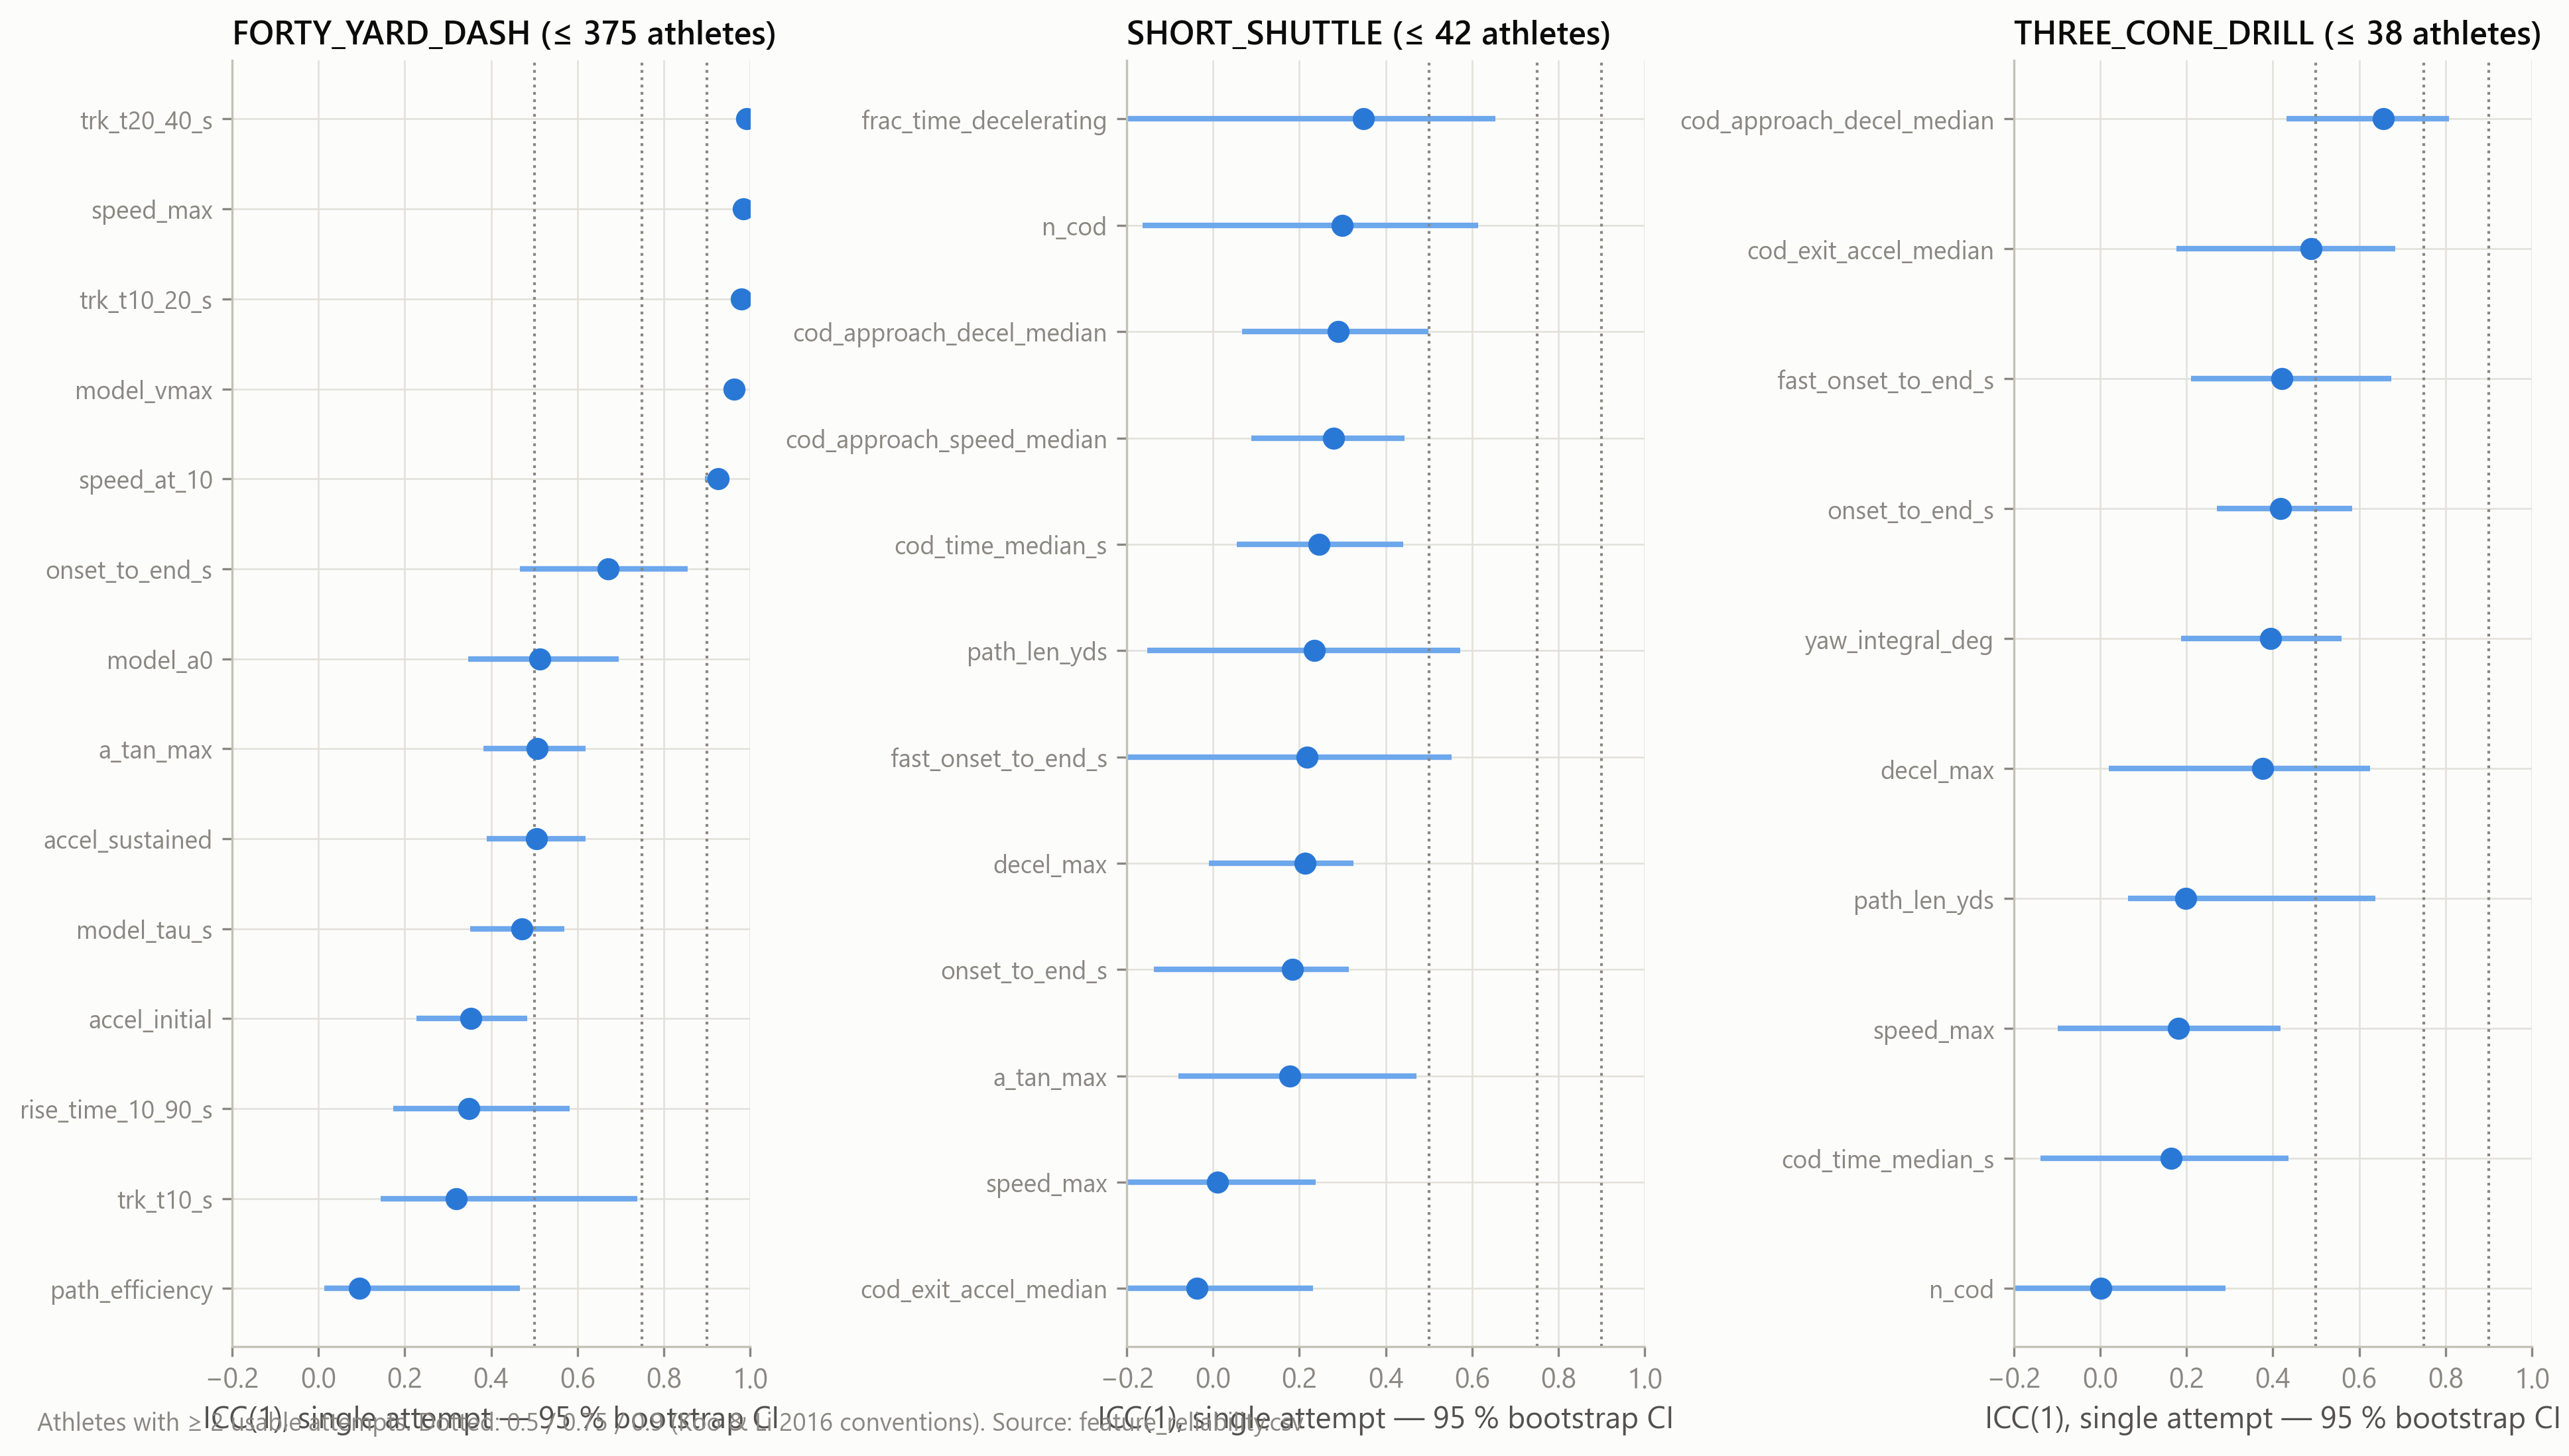

drill,feature,n_athletes,icc1,icc1_ci_lo,icc1_mean_k,typical_error
str,str,i64,f64,f64,f64,f64
"""BACK_PEDAL_AND_TRANSITION_45_D…","""path_efficiency""",119,0.962878,0.949251,0.981088,0.034813
"""BACK_PEDAL_AND_TRANSITION_45_D…","""lateral_extent_yds""",119,0.94604,0.925121,0.972272,1.320975
"""BACK_PEDAL_AND_TRANSITION_45_D…","""time_above_4yds_s""",119,0.933082,0.904484,0.965383,0.615521
"""BACK_PEDAL_AND_TRANSITION_45_D…","""path_len_yds""",119,0.932045,0.903351,0.964827,4.63597
"""BACK_PEDAL_AND_TRANSITION_45_D…","""yaw_integral_deg""",119,0.921419,0.882196,0.959103,20.407596
…,…,…,…,…,…,…
"""FORTY_YARD_DASH""","""time_above_6yds_s""",375,0.933393,0.91937,0.965549,0.053417
"""FORTY_YARD_DASH""","""speed_at_10""",375,0.92591,0.89586,0.96153,0.145667
"""FORTY_YARD_DASH""","""accel_integral_pos""",375,0.913197,0.878352,0.954629,0.241122


In [5]:
# 6. Saved figure (written by combine_analytics) + 7. shortlist export
#    Shortlist = labelled good/excellent only: requires ≥ min_athletes_label athletes with ≥ 2 attempts,
#    a non-degenerate distribution and a CI lower bound ≥ 0.75.
from IPython.display import Image, display
fig = store.figures_dir / 'm2_feature_reliability.png'
if fig.exists():
    display(Image(filename=str(fig), width=1000))
shortlist = (rel.filter((pl.col('cohort') == 'all') & pl.col('reliability').is_in(['good', 'excellent']))
                .select('drill', 'feature', 'n_athletes', 'icc1', 'icc1_ci_lo', 'icc1_mean_k', 'typical_error')
                .sort('drill', 'icc1_ci_lo', descending=[False, True]))
store.export_csv(shortlist, 'reliable_feature_shortlist', 'Features with ICC(1) CI lower bound ≥ 0.75 (pooled)',
                 parquet=True)
shortlist

## 8. Parquet persistence
Reliability results are compact → CSV for reading plus a Parquet twin for typed reuse (`feature_reliability.{csv,parquet}`, `reliable_feature_shortlist.{csv,parquet}`). Reload: `pl.read_parquet(store.tables_dir / 'feature_reliability.parquet')` or `CombineMovementAnalytics(cfg).load_table('feature_reliability')`. Inputs are the persisted M2 datasets; nothing is recomputed from tracking.

Labels: `insufficient_athletes` (< 10 athletes with ≥ 2 attempts, no ICC), `insufficient_for_label` (ICC reported, < 20 athletes), `degenerate_distribution` (≥ 80 % identical values), otherwise poor/moderate/good/excellent from the CI lower bound. Only the first 4 attempts per athlete enter.

## 9. Interpretation (fill in ONLY from executed outputs)
* Forty: is `model_tau_s` / `model_a0` as reliable as `model_vmax`? Is the tracked `trk_t10_s` more or less reliable than the tracked flying intervals (`trk_t10_20_s`, `trk_t20_40_s`)? _…_
* Agility: are COD-level features (`cod_time_median_s`, `cod_exit_accel_median`) reliable enough to carry athlete information? _…_
* Peak (single-frame) vs robust (quantile / rolling) features — does robustness buy reliability? _…_
* Cohort differences in ICC (2025 lower noise) _…_
* Systematic attempt-2 − attempt-1 drift (learning / fatigue) _…_

## 10. Limitations
* Most agility athletes have only 1–2 attempts → wide CIs; ICC(1) assumes exchangeable attempts.
* Athletes choose whether to repeat a drill (selection): those with ≥ 2 attempts may differ systematically.
* Labels use conventional cut-offs applied to the CI lower bound (conservative), not validated thresholds.

## 11. Next analysis
Use the reliable shortlist for athlete fingerprints (M2 continuation) and as the Combine side of the Combine → NFL transfer analyses (M4).